<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_27.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Deep Belief Network (DBN) Representation Learning
This notebook demonstrates pre-training features on unlabelled MNIST digits using a Stacked Restricted Boltzmann Machine (RBM) and fine-tuning with only 1,000 labelled samples.

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize and flatten images
x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test.reshape(-1, 784).astype("float32") / 255.0

# Split into unlabelled (all train) and a small labelled subset (1,000 samples)
num_labelled = 1000
idx = np.random.choice(len(x_train), num_labelled, replace=False)
x_train_labelled = x_train[idx]
y_train_labelled = y_train[idx]

print(f"Unlabelled dataset size (for pretraining): {x_train.shape[0]}")
print(f"Labelled dataset size (for finetuning): {x_train_labelled.shape[0]}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Unlabelled dataset size (for pretraining): 60000
Labelled dataset size (for finetuning): 1000


### Task 1: Train two stacked RBMs layer-by-layer (784 -> 500 -> 250)
We implement a custom RBM training loop using Contrastive Divergence (CD-1).

In [2]:
class RBM:
    def __init__(self, visible_dim, hidden_dim, lr=0.01, epochs=15, batch_size=64):
        self.visible_dim = visible_dim
        self.hidden_dim = hidden_dim
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size

        # Initialize weights and biases
        self.W = tf.Variable(tf.random.normal([visible_dim, hidden_dim], stddev=0.01), dtype=tf.float32)
        self.v_bias = tf.Variable(tf.zeros([visible_dim]), dtype=tf.float32)
        self.h_bias = tf.Variable(tf.zeros([hidden_dim]), dtype=tf.float32)

    def sample_hidden(self, v):
        h_prob = tf.nn.sigmoid(tf.matmul(v, self.W) + self.h_bias)
        h_sample = tf.nn.relu(tf.sign(h_prob - tf.random.uniform(tf.shape(h_prob))))
        return h_prob, h_sample

    def sample_visible(self, h):
        v_prob = tf.nn.sigmoid(tf.matmul(h, tf.transpose(self.W)) + self.v_bias)
        v_sample = tf.nn.relu(tf.sign(v_prob - tf.random.uniform(tf.shape(v_prob))))
        return v_prob, v_sample

    def train(self, data):
        dataset = tf.data.Dataset.from_tensor_slices(data).shuffle(10000).batch(self.batch_size)
        for epoch in range(self.epochs):
            loss_list = []
            for batch in dataset:
                with tf.GradientTape() as tape:
                    v0 = batch
                    h0_prob, h0_sample = self.sample_hidden(v0)
                    v1_prob, v1_sample = self.sample_visible(h0_sample)
                    h1_prob, _ = self.sample_hidden(v1_sample)

                    # Positive and negative phase reconstructions
                    pos_grad = tf.matmul(tf.transpose(v0), h0_prob)
                    neg_grad = tf.matmul(tf.transpose(v1_prob), h1_prob)

                    # Compute loss as Mean Squared Reconstruction Error
                    reconstruction_error = tf.reduce_mean(tf.square(v0 - v1_prob))
                    loss_list.append(reconstruction_error)

                # Gradient updates manually mimicking CD-1 rule
                dW = (pos_grad - neg_grad) / tf.cast(tf.shape(v0)[0], tf.float32)
                dv = tf.reduce_mean(v0 - v1_prob, axis=0)
                dh = tf.reduce_mean(h0_prob - h1_prob, axis=0)

                self.W.assign_add(self.lr * dW)
                self.v_bias.assign_add(self.lr * dv)
                self.h_bias.assign_add(self.lr * dh)

            print(f"Epoch {epoch+1}/{self.epochs} - Reconstruction Error: {np.mean(loss_list):.4f}")

# Train First RBM (784 -> 500)
print("Training RBM 1 (784 -> 500)...")
rbm1 = RBM(visible_dim=784, hidden_dim=500, epochs=10, lr=0.05)
rbm1.train(x_train)

# Generate activations of RBM 1 to feed into RBM 2
_, h1_train = rbm1.sample_hidden(x_train)

# Train Second RBM (500 -> 250)
print("\nTraining RBM 2 (500 -> 250)...")
rbm2 = RBM(visible_dim=500, hidden_dim=250, epochs=10, lr=0.05)
rbm2.train(h1_train)

Training RBM 1 (784 -> 500)...
Epoch 1/10 - Reconstruction Error: 0.0302
Epoch 2/10 - Reconstruction Error: 0.0167
Epoch 3/10 - Reconstruction Error: 0.0141
Epoch 4/10 - Reconstruction Error: 0.0129
Epoch 5/10 - Reconstruction Error: 0.0123
Epoch 6/10 - Reconstruction Error: 0.0118
Epoch 7/10 - Reconstruction Error: 0.0116
Epoch 8/10 - Reconstruction Error: 0.0114
Epoch 9/10 - Reconstruction Error: 0.0112
Epoch 10/10 - Reconstruction Error: 0.0111

Training RBM 2 (500 -> 250)...
Epoch 1/10 - Reconstruction Error: 0.0706
Epoch 2/10 - Reconstruction Error: 0.0514
Epoch 3/10 - Reconstruction Error: 0.0460
Epoch 4/10 - Reconstruction Error: 0.0434
Epoch 5/10 - Reconstruction Error: 0.0418
Epoch 6/10 - Reconstruction Error: 0.0408
Epoch 7/10 - Reconstruction Error: 0.0400
Epoch 8/10 - Reconstruction Error: 0.0395
Epoch 9/10 - Reconstruction Error: 0.0391
Epoch 10/10 - Reconstruction Error: 0.0387


### Task 2: Visualize the learned weights of the first layer as image filters

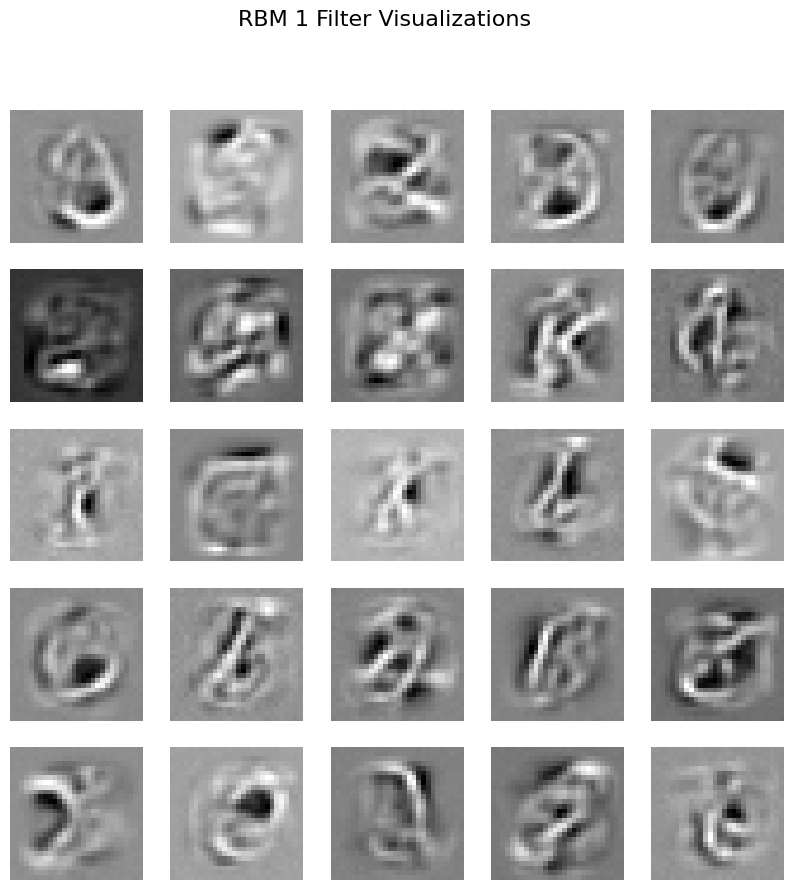

In [3]:
weights = rbm1.W.numpy()
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(weights[:, i].reshape(28, 28), cmap='gray')
    plt.axis('off')
plt.suptitle("RBM 1 Filter Visualizations", fontsize=16)
plt.show()

### Task 3: Transfer weights into a Keras dense network and fine-tune with the labelled data

In [4]:
def create_dbn_model(pretrained=True):
    model = keras.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(500, activation='sigmoid', name='layer1'),
        layers.Dense(250, activation='sigmoid', name='layer2'),
        layers.Dense(10, activation='softmax', name='output')
    ])

    if pretrained:
        # Transfer weights and biases from the trained RBMs
        model.get_layer('layer1').set_weights([rbm1.W.numpy(), rbm1.h_bias.numpy()])
        model.get_layer('layer2').set_weights([rbm2.W.numpy(), rbm2.h_bias.numpy()])

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

dbn_model = create_dbn_model(pretrained=True)
print("Fine-tuning DBN...")
history_dbn = dbn_model.fit(x_train_labelled, y_train_labelled, validation_data=(x_test, y_test), epochs=30, batch_size=32, verbose=1)

Fine-tuning DBN...
Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.2990 - loss: 2.0895 - val_accuracy: 0.6169 - val_loss: 1.5633
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.7260 - loss: 1.2713 - val_accuracy: 0.8013 - val_loss: 1.0341
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8470 - loss: 0.8478 - val_accuracy: 0.8495 - val_loss: 0.7569
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.8820 - loss: 0.6130 - val_accuracy: 0.8739 - val_loss: 0.6027
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9090 - loss: 0.4673 - val_accuracy: 0.8875 - val_loss: 0.5084
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9350 - loss: 0.3673 - val_accuracy: 0.8966 - val_loss: 0.4456
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9520 - loss: 0.2935 - val_accuracy: 0.9030 - val_loss: 0.4015
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9710 - loss: 0.2373 - val_a

### Task 4: Train the same network from random initialization for comparison

In [5]:
random_model = create_dbn_model(pretrained=False)
print("Training Randomly Initialized Model...")
history_random = random_model.fit(x_train_labelled, y_train_labelled, validation_data=(x_test, y_test), epochs=30, batch_size=32, verbose=1)

Training Randomly Initialized Model...
Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.2950 - loss: 2.0884 - val_accuracy: 0.5693 - val_loss: 1.6903
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.6460 - loss: 1.3791 - val_accuracy: 0.7634 - val_loss: 1.0464
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.7890 - loss: 0.8682 - val_accuracy: 0.8178 - val_loss: 0.7351
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.8390 - loss: 0.6237 - val_accuracy: 0.8392 - val_loss: 0.6025
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.8730 - loss: 0.4891 - val_accuracy: 0.8528 - val_loss: 0.5345
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.8960 - loss: 0.4013 - val_accuracy: 0.8586 - val_loss: 0.4908
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9130 - loss: 0.3375 - val_accuracy: 0.8674 - val_loss: 0.4574
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9330 - 

### Task 5: Compare accuracy and plot learned representations in 2-D using t-SNE

Test Accuracy with DBN pretraining: 0.9257
Test Accuracy with Random initialization: 0.8900
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


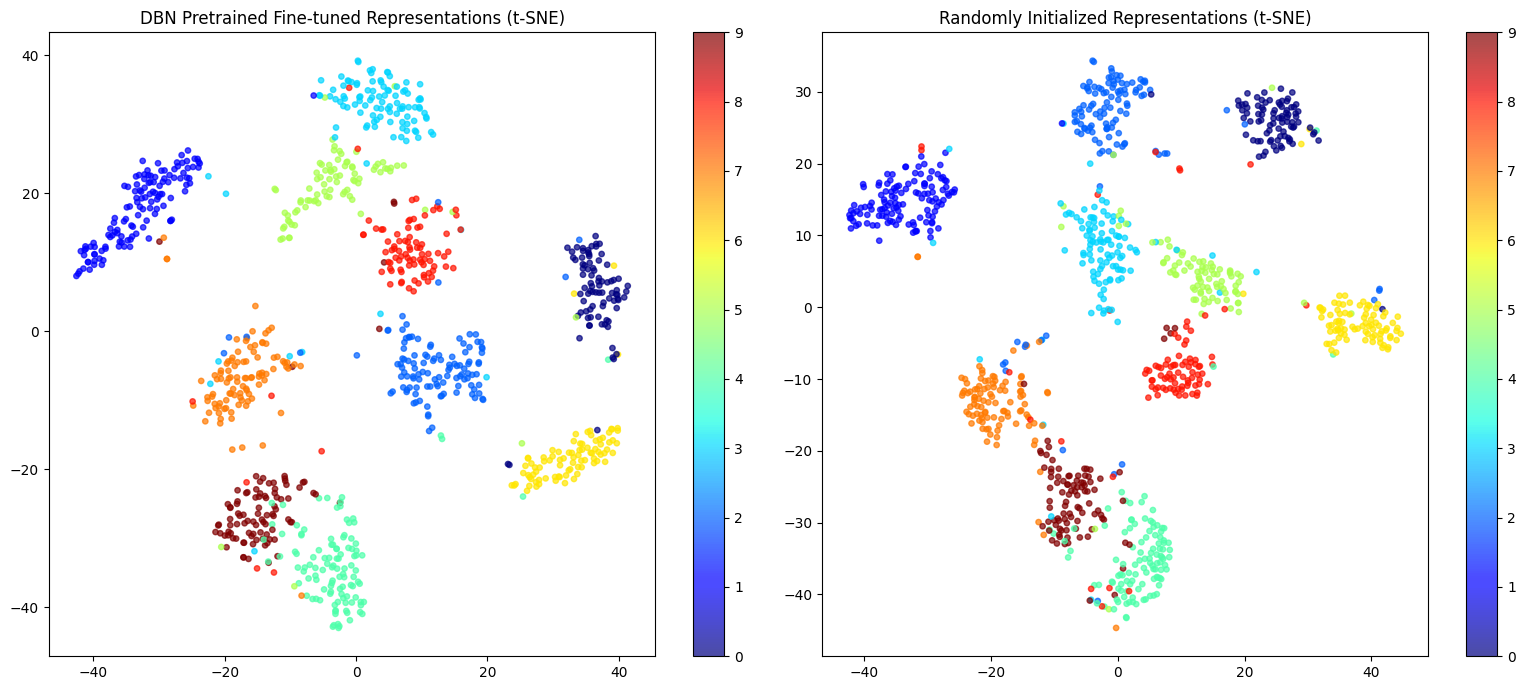

In [8]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Compare accuracy
dbn_acc = dbn_model.evaluate(x_test, y_test, verbose=0)[1]
random_acc = random_model.evaluate(x_test, y_test, verbose=0)[1]
print(f"Test Accuracy with DBN pretraining: {dbn_acc:.4f}")
print(f"Test Accuracy with Random initialization: {random_acc:.4f}")

# Take a subset of test dataset for visualization
num_vis = 1000
x_vis = x_test[:num_vis]
y_vis = y_test[:num_vis]

# Extract representations from the second hidden layer (250 units)
# Construct functional feature extractors to bypass Keras 3 sequential input resolution issues
inputs = keras.Input(shape=(784,))

x_dbn = dbn_model.get_layer('layer1')(inputs)
features_dbn_layer = dbn_model.get_layer('layer2')(x_dbn)
feature_extractor_dbn = keras.Model(inputs=inputs, outputs=features_dbn_layer)

x_rand = random_model.get_layer('layer1')(inputs)
features_random_layer = random_model.get_layer('layer2')(x_rand)
feature_extractor_random = keras.Model(inputs=inputs, outputs=features_random_layer)

features_dbn = feature_extractor_dbn.predict(x_vis)
features_random = feature_extractor_random.predict(x_vis)

# Apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_dbn = tsne.fit_transform(features_dbn)
tsne_random = tsne.fit_transform(features_random)

# Plot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# DBN representation plot
scatter1 = axes[0].scatter(tsne_dbn[:, 0], tsne_dbn[:, 1], c=y_vis, cmap='jet', alpha=0.7, s=15)
axes[0].set_title("DBN Pretrained Fine-tuned Representations (t-SNE)")
fig.colorbar(scatter1, ax=axes[0])

# Random initialization representation plot
scatter2 = axes[1].scatter(tsne_random[:, 0], tsne_random[:, 1], c=y_vis, cmap='jet', alpha=0.7, s=15)
axes[1].set_title("Randomly Initialized Representations (t-SNE)")
fig.colorbar(scatter2, ax=axes[1])

plt.tight_layout()
plt.show()